# Avance 4. Modelos alternativos
**Proyecto Berry-Vision — Clasificación de arándanos defectuosos mediante visión computacional e inteligencia artificial**

**Equipo #6** · Proyecto Integrador MNA · Metodología CRISP-ML(Q), fase *Modeling*

| Integrante | Matrícula |
|---|---|
| José Luis Parada Gutiérrez | A00939669 |
| Kevin Rosario Cota Rodríguez | A01796705 |
| Rolando David Villarreal Martínez | A00609894 |

---
**Objetivos del avance**
- 3.3 Explorar una gama diversa de técnicas y enfoques para identificar el de mejor desempeño en el conjunto de datos.
- 3.4 Encontrar la configuración óptima que maximiza el rendimiento del modelo.

**Punto de partida.** El Avance 3 fijó el baseline (regresión logística), la métrica y los criterios mínimos sobre las 15 características del Avance 2. Aquí se construyen **ocho modelos alternativos individuales (sin ensambles) de familias distintas** —seis sobre las características tabulares y dos sobre las imágenes (ResNet18 preentrenada y una CNN propia, a partir del trabajo de José Luis)—, se comparan entre sí y contra el baseline con un mismo protocolo, se **ajustan los dos mejores** y se **elige un modelo individual final**. El baseline del Avance 3 (regresión logística) no compite por el ajuste: es la **referencia** que cada alternativa debe igualar o superar para justificarse.

| Paso solicitado | Sección |
|---|---|
| Construir ≥ 6 modelos individuales de algoritmos variados (más el baseline como referencia) | 2 |
| Compararlos (métrica principal, ≥ 2 métricas más y tiempos) | 3 |
| Seleccionar los dos mejores alternativos | 4 |
| Ajustar los dos mejores (búsqueda de hiperparámetros) | 5 |
| Elegir el modelo individual final | 6 |

**Protocolo (el mismo del Avance 3).** Las particiones train/val/test y los bloques de captura son los del Avance 2. La comparación, la selección y el ajuste usan **solo validación cruzada agrupada sobre *train*** (un bloque nunca se parte entre pliegues); *validación* es una comprobación independiente; el conjunto de **prueba se toca una sola vez**, en la sección 7.

## 1. Configuración y datos

In [1]:
import os, sys, time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.metrics import (average_precision_score, roc_auc_score, recall_score, precision_score, fbeta_score,
                             balanced_accuracy_score, matthews_corrcoef, accuracy_score, confusion_matrix,
                             precision_recall_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60, "display.width", 200)
SEED = 42

# ---- Rutas: Colab (Drive) o ejecución local -------------------------------------------------
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    _base = Path("/content/drive/MyDrive/ProyectoIntegrador/Datos")
else:
    _base = next((p for p in [Path("../Datos"), Path("Datos")] if p.exists()), Path("../Datos"))
A2_DIR = Path(os.environ.get("BERRY_IN_DIR", _base / "resultados_avance2"))      # tablas del Avance 2
A3_DIR = Path(os.environ.get("BERRY_A3_DIR", _base / "resultados_avance3"))      # baseline del Avance 3
OUT_DIR = Path(os.environ.get("BERRY_OUT_DIR", _base / "resultados_avance4"))    # salidas de este avance
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Avance 2:", A2_DIR.resolve(), "\nAvance 3:", A3_DIR.resolve(), "\nSalidas :", OUT_DIR.resolve(), "| Colab:", IN_COLAB)

Avance 2: C:\Users\Rolando\Documents\Personal\Tec Postgrado\Proyecto Integrador\Datos\resultados_avance2 
Avance 3: C:\Users\Rolando\Documents\Personal\Tec Postgrado\Proyecto Integrador\Datos\resultados_avance3 
Salidas : C:\Users\Rolando\Documents\Personal\Tec Postgrado\Proyecto Integrador\Datos\resultados_avance4 | Colab: False


In [2]:
TR, VA, TE = [pd.read_csv(A2_DIR / f"features_seleccionadas_{s}.csv") for s in ("train", "val", "test")]
META = ["crop_id", "grupo", "clase", "particion", "y"]
FEATS = [c for c in TR.columns if c not in META + ["defecto"]]
assert list(TR[FEATS].columns) == list(VA[FEATS].columns) == list(TE[FEATS].columns)
assert not set(TR.grupo) & set(VA.grupo) and not set(TR.grupo) & set(TE.grupo) and not set(VA.grupo) & set(TE.grupo)

Xtr, ytr, gtr = TR[FEATS], TR.y.values, TR.grupo.values
Xva, yva = VA[FEATS], VA.y.values
Xte, yte, gte = TE[FEATS], TE.y.values, TE.grupo.values
DEV = pd.concat([TR, VA], ignore_index=True)
Xdev, ydev = DEV[FEATS], DEV.y.values

display(pd.DataFrame({"recortes": [len(TR), len(VA), len(TE)], "malos": [ytr.sum(), yva.sum(), yte.sum()],
                      "% malos": [ytr.mean() * 100, yva.mean() * 100, yte.mean() * 100],
                      "bloques": [TR.grupo.nunique(), VA.grupo.nunique(), TE.grupo.nunique()]}, index=["train", "val", "test"]).round(1))
print(f"{len(FEATS)} características (ya estandarizadas con parámetros de train): {FEATS}")

# Configuración del baseline fijada en el Avance 3
cfg3 = json.load(open(A3_DIR / "config_baseline.json"))
C_BASE, U_BASE = float(cfg3["C"]), float(cfg3["umbral"])
print(f"Baseline del Avance 3: regresión logística con C = {C_BASE:g} y umbral = {U_BASE:.3f}")

,recortes,malos,% malos,bloques
train,258,95,36.8,60
val,45,16,35.6,11
test,50,20,40.0,13


15 características (ya estandarizadas con parámetros de train): ['rojez_std', 'rojez_p99', 'pct_marron', 'b_p95', 'rojez_p95', 'rojizo_ord', 'grad_p95', 'rugosidad_textura', 'indice_lesion', 'glcm_homogeneidad', 'densidad_bordes', 'nitidez', 'lbp_p6', 'matiz', 'a_medio']
Baseline del Avance 3: regresión logística con C = 1 y umbral = 0.383


### 1.1 Imágenes: espacio de entrada de los modelos de visión
Además de la tabla de 15 características, dos modelos trabajan **directamente sobre los recortes** (los mismos 353 frutos, con el mismo identificador, las mismas particiones y los mismos bloques de captura):

| Espacio | Entrada | Modelos |
|---|---|---|
| `tab` | 15 características estandarizadas | Todos los modelos tabulares |
| `emb` | Embedding de 512 dimensiones de una **ResNet18 preentrenada en ImageNet con el *backbone* congelado** (se extrae una sola vez) | ResNet18 + regresión logística |
| `img` | Recorte de 128×128 píxeles, normalizado con la media y desviación del conjunto de entrenamiento | CNN propia |

El recorte sigue el criterio del Avance 1 (cuadrado de lado 2·(radio + 20) alrededor del fruto). La arquitectura de la CNN y el uso de ResNet18 congelada provienen del trabajo de **José Luis** (`Avance3_Equipo6_4_Modelos`); aquí se evalúan con el mismo protocolo que los demás modelos (validación cruzada agrupada) en lugar de una única partición de validación. Si la carpeta de imágenes no está disponible, la libreta omite estos dos modelos y compara solo los tabulares.

In [3]:
# ---- Imágenes (opcional): sin ellas se omiten los dos modelos de visión ------------------------------------
import copy
_cands = [os.environ.get("BERRY_IMG_DIR"), "/content/drive/MyDrive/ProyectoIntegrador/Semana4/v2" if IN_COLAB else None, "../Datos/Semana4/v2", "Datos/Semana4/v2"]
IMG_ROOT = next((Path(p) for p in _cands if p and (Path(p) / "output").exists() and (Path(p) / "etiquetas.csv").exists()), None)
HAY_IMG = IMG_ROOT is not None
ESPACIO = {}                                             # espacio de entrada de cada modelo (por defecto: tab)
ESPACIOS_X = {"tab": dict(tr=Xtr, va=Xva, dev=Xdev, te=Xte)}
MODELOS_IMG = {}
T_EMB = 0.0
if HAY_IMG:
    try:
        import torch, torch.nn as nn
        from PIL import Image
        from torchvision import models as tvm
        from sklearn.base import BaseEstimator, ClassifierMixin
        from sklearn.pipeline import Pipeline
        from sklearn.preprocessing import StandardScaler
        from sklearn.decomposition import PCA
        torch.set_num_threads(max(1, min(8, os.cpu_count() or 2)))

        et = pd.read_csv(IMG_ROOT / "etiquetas.csv", encoding="utf-8-sig")
        et["crop_id"] = et.nombre.str.replace(".png", "", regex=False)
        ALL = pd.concat([TR, VA, TE], ignore_index=True)[["crop_id", "grupo", "y"]].merge(
            et[["crop_id", "cx", "cy", "radio"]], on="crop_id", how="left", validate="one_to_one")
        assert ALL.cx.notna().all(), "hay recortes de las tablas sin imagen"

        def recorte(r, lado, pad=20):
            im = Image.open(IMG_ROOT / "output" / f"{r.crop_id}.png").convert("RGB"); w, h = im.size
            R = int(round(r.radio)) + pad; cx, cy = int(round(r.cx)), int(round(r.cy))
            c = im.crop((max(0, cx - R), max(0, cy - R), min(w, cx + R), min(h, cy + R)))
            return np.asarray(c.resize((lado, lado), Image.BILINEAR))
        I128 = np.stack([recorte(r, 128) for r in ALL.itertuples()]); I224 = np.stack([recorte(r, 224) for r in ALL.itertuples()])

        # (a) Embeddings de ResNet18 congelada (se calculan una vez; no hay entrenamiento del backbone)
        w = tvm.ResNet18_Weights.DEFAULT; red = tvm.resnet18(weights=w); red.fc = nn.Identity(); red.eval()
        mu = torch.tensor(w.transforms().mean).view(1, 3, 1, 1); sd = torch.tensor(w.transforms().std).view(1, 3, 1, 1)
        x = (torch.from_numpy(I224).permute(0, 3, 1, 2).float() / 255 - mu) / sd
        t0 = time.perf_counter()
        with torch.no_grad():
            EMB = torch.cat([red(x[i:i + 64]) for i in range(0, len(x), 64)]).numpy()
        T_EMB = time.perf_counter() - t0
        del x

        # (b) Tensor de la CNN propia (normalizado con estadísticos de train)
        T128 = torch.from_numpy(I128).permute(0, 3, 1, 2).float() / 255
        T128 = (T128 - T128[:len(TR)].mean((0, 2, 3), keepdim=True)) / T128[:len(TR)].std((0, 2, 3), keepdim=True)
        G_ALL = ALL.grupo.values

        class CNNBerry(BaseEstimator, ClassifierMixin):
            # CNN pequeña (4 bloques conv + pooling global) entrenada desde cero; ~20 % de los bloques de entrenamiento
            # se reserva para detener el entrenamiento (early stopping por AP)
            def __init__(self, base=16, dropout=0.4, activation="relu", lr=5e-4, weight_decay=1e-4, epochs=30, patience=6, batch=32, seed=SEED):
                self.base, self.dropout, self.activation, self.lr = base, dropout, activation, lr
                self.weight_decay, self.epochs, self.patience, self.batch, self.seed = weight_decay, epochs, patience, batch, seed
            def _red(self):
                act = {"relu": nn.ReLU, "leaky_relu": nn.LeakyReLU, "elu": nn.ELU}[self.activation]; b = self.base
                blk = lambda i, o, pool=True: [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), act()] + ([nn.MaxPool2d(2)] if pool else [])
                return nn.Sequential(*blk(3, b), *blk(b, 2 * b), *blk(2 * b, 4 * b), *blk(4 * b, 8 * b, False),
                                     nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(8 * b, 64), act(), nn.Dropout(self.dropout), nn.Linear(64, 1))
            def _p(self, idx):
                self.red_.eval(); out = []
                with torch.no_grad():
                    for i in range(0, len(idx), 128): out.append(torch.sigmoid(self.red_(T128[idx[i:i + 128]]).squeeze(1)))
                return torch.cat(out).numpy()
            def fit(self, X, y):
                idx = X["idx"].values.astype(int); y = np.asarray(y)
                torch.manual_seed(self.seed); rng = np.random.default_rng(self.seed)
                ti, vi = next(StratifiedGroupKFold(5, shuffle=True, random_state=self.seed).split(idx, y, G_ALL[idx]))
                self.red_ = self._red(); opt = torch.optim.AdamW(self.red_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
                perdida = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([(y[ti] == 0).sum() / max((y[ti] == 1).sum(), 1)], dtype=torch.float32))
                mejor, estado, espera = -1.0, None, 0
                for ep in range(self.epochs):
                    self.red_.train(); orden = rng.permutation(ti)
                    for i in range(0, len(orden), self.batch):
                        b = orden[i:i + self.batch]
                        if len(b) < 2: continue
                        xb = T128[idx[b]]                                   # aumento de datos por lote: giros y rotaciones de 90°
                        if rng.random() < .5: xb = xb.flip(3)
                        if rng.random() < .5: xb = xb.flip(2)
                        xb = torch.rot90(xb, int(rng.integers(0, 4)), (2, 3))
                        opt.zero_grad(); perdida(self.red_(xb).squeeze(1), torch.tensor(y[b], dtype=torch.float32)).backward(); opt.step()
                    ap = average_precision_score(y[vi], self._p(idx[vi]))
                    if ap > mejor + 1e-4: mejor, estado, espera = ap, copy.deepcopy(self.red_.state_dict()), 0
                    else:
                        espera += 1
                        if espera >= self.patience: break
                self.red_.load_state_dict(estado); self.classes_ = np.array([0, 1]); self.mejor_epoca_ = ep + 1 - espera
                return self
            def predict_proba(self, X):
                p = self._p(X["idx"].values.astype(int)); return np.column_stack([1 - p, p])

        n_tr, n_va = len(TR), len(VA)
        def partir(F):
            return dict(tr=F.iloc[:n_tr].reset_index(drop=True), va=F.iloc[n_tr:n_tr + n_va].reset_index(drop=True),
                        dev=F.iloc[:n_tr + n_va].reset_index(drop=True), te=F.iloc[n_tr + n_va:].reset_index(drop=True))
        ESPACIOS_X["emb"] = partir(pd.DataFrame(EMB, columns=[f"e{i}" for i in range(EMB.shape[1])]))
        ESPACIOS_X["img"] = partir(pd.DataFrame({"idx": np.arange(len(ALL))}))
        MODELOS_IMG = {
            "ResNet18 + reg. logística": Pipeline([("sc", StandardScaler()), ("pca", PCA(64, random_state=SEED)),
                                                   ("clf", LogisticRegression(C=0.05, class_weight="balanced", max_iter=5000))]),
            "CNN propia": CNNBerry(),
        }
        ESPACIO.update({"ResNet18 + reg. logística": "emb", "CNN propia": "img"})
        print(f"Imágenes: {IMG_ROOT.resolve()} · {len(ALL)} recortes · embeddings ResNet18 {EMB.shape} calculados en {T_EMB:.1f} s")
    except Exception as e:
        HAY_IMG, MODELOS_IMG = False, {}
        print("Se omiten los modelos de imagen:", repr(e)[:300])
else:
    print("No se encontró la carpeta de imágenes (Semana4/v2): se omiten los dos modelos de visión.")
ES = lambda m: ESPACIOS_X[ESPACIO.get(m, "tab")]            # tablas (train/val/dev/test) del espacio de entrada de un modelo

Imágenes: C:\Users\Rolando\Documents\Personal\Tec Postgrado\Proyecto Integrador Investigación\Semana 6\Semana4\v2 · 353 recortes · embeddings ResNet18 (353, 512) calculados en 5.0 s


## 2. Métricas, protocolo y modelos candidatos

### 2.1 Qué se mide
Se mantiene el criterio del Avance 3: el error caro es el **falso negativo** (un fruto malo que pasa como bueno) y la clase de interés es la minoritaria (≈ 4 de cada 10 frutos). Como los modelos no producen probabilidades comparables al umbral 0.5 (algunos no admiten pesos de clase), la comparación se hace con métricas **independientes del umbral**, calculadas con predicciones fuera de pliegue:

| Métrica | Papel | Por qué |
|---|---|---|
| **AP** (*average precision*) | **Principal** (ordena la tabla y decide la selección) | Resume toda la curva precisión–recall; su referencia al azar es la prevalencia |
| **Precisión con recall ≥ 0.80** | Secundaria | Traduce el criterio de negocio del Avance 3 (C2/C3): ¿cuánta precisión queda cuando se exige detectar al menos 8 de cada 10 malos? |
| ROC-AUC | Secundaria | Capacidad global de ordenar *malo* sobre *bueno* |
| Tiempo de ajuste y de predicción | Costo | Requisito de la línea en tiempo real y de reentrenamiento |

El recall y la precisión a un umbral concreto se reportan para los dos modelos ajustados y para el modelo final (secciones 5–7), cuando ya se fijó el umbral con la regla del Avance 3.

### 2.2 Los modelos
Ocho algoritmos **alternativos individuales** de familias distintas (ninguno es un ensamble; seis tabulares y dos de imagen), más el baseline del Avance 3 como referencia. Todos parten de hiperparámetros razonables, **sin ajustar**; el ajuste se hace solo con los dos mejores alternativos.

| Modelo | Familia | Por qué entra | Interpretabilidad |
|---|---|---|---|
| *Regresión logística* | *Lineal discriminativo* | *Baseline del Avance 3 (referencia, no compite por el ajuste)* | *Alta* |
| LDA | Lineal generativo | Supone gaussianas con covarianza común; muy estable con pocos datos | Alta |
| Naive Bayes gaussiano | Probabilístico | Supone independencia entre variables; casi sin hiperparámetros | Media |
| kNN | Basado en instancias | Sin entrenamiento; capta fronteras locales | Baja |
| Árbol de decisión | Reglas | Reglas legibles e interacciones entre variables | Alta (si es poco profundo) |
| SVM con kernel RBF | Márgenes / kernel | Frontera no lineal suave; buena con pocas muestras | Baja |
| Red neuronal (MLP) | Redes | Aprende combinaciones no lineales de variables | Baja |
| ResNet18 + regresión logística | *Transfer learning* (backbone congelado) | Conocimiento visual de ImageNet: se extrae el embedding de 512 dimensiones una sola vez y se entrena una cabeza lineal | Baja |
| CNN propia | Red convolucional desde cero | Aprende filtros directamente de los píxeles; arquitectura pequeña (4 bloques convolucionales + pooling global) | Baja |

In [4]:
BETA, REC_OBJ = 2.0, 0.80
PREV = float(ytr.mean())

def prec_at_rec(y, p, rec=REC_OBJ):
    # Mayor precisión alcanzable con recall >= rec (curva precisión-recall)
    pr, rc, _ = precision_recall_curve(y, p)
    ok = rc[:-1] >= rec
    return float(pr[:-1][ok].max()) if ok.any() else 0.0

def metricas(y, p, umbral=0.5):
    yhat = (p >= umbral).astype(int)
    return {"AP": average_precision_score(y, p), "ROC_AUC": roc_auc_score(y, p), "Prec@Rec80": prec_at_rec(y, p),
            "recall_malo": recall_score(y, yhat), "precision_malo": precision_score(y, yhat, zero_division=0),
            "F2": fbeta_score(y, yhat, beta=BETA), "bal_acc": balanced_accuracy_score(y, yhat),
            "MCC": matthews_corrcoef(y, yhat), "accuracy": accuracy_score(y, yhat)}

def folds(y, g, reps=3, k=5, seed=SEED):
    # CV agrupada y estratificada: cada bloque de captura queda en un solo pliegue
    for r in range(reps):
        for tri, tei in StratifiedGroupKFold(k, shuffle=True, random_state=seed + r).split(np.zeros(len(y)), y, g):
            yield r, tri, tei

def cv_modelo(modelo, X, y, g, reps=3):
    # Devuelve métricas fuera de pliegue (promedio de repeticiones), desviación entre pliegues y tiempos
    oof = np.zeros((reps, len(y))); ap_pl, t_fit, t_pred = [], [], []
    for r, tri, tei in folds(y, g, reps):
        m = clone(modelo)
        t0 = time.perf_counter(); m.fit(X.iloc[tri], y[tri]); t1 = time.perf_counter()
        p = m.predict_proba(X.iloc[tei])[:, 1]; t2 = time.perf_counter()
        oof[r, tei] = p; ap_pl.append(average_precision_score(y[tei], p)); t_fit.append(t1 - t0); t_pred.append((t2 - t1) / len(tei))
    por_rep = pd.DataFrame([{k: v for k, v in metricas(y, oof[r]).items() if k in ("AP", "ROC_AUC", "Prec@Rec80")} for r in range(reps)])
    return {**por_rep.mean().to_dict(), "AP_desv": float(np.std(ap_pl)), "ajuste_ms": 1e3 * np.mean(t_fit), "pred_ms_por_fruto": 1e3 * np.mean(t_pred)}, oof

MODELOS = {
    "Regresión logística": LogisticRegression(C=C_BASE, class_weight="balanced", max_iter=5000),
    "LDA":                 LinearDiscriminantAnalysis(),
    "Naive Bayes":         GaussianNB(),
    "kNN":                 KNeighborsClassifier(15),
    "Árbol de decisión":   DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, class_weight="balanced", random_state=SEED),
    "SVM RBF":             SVC(C=1.0, probability=True, class_weight="balanced", random_state=SEED),
    "MLP":                 MLPClassifier((32,), alpha=1e-3, max_iter=1000, random_state=SEED),
}
MODELOS.update(MODELOS_IMG)                                           # modelos de imagen (si hay imágenes)
BASELINE = "Regresión logística"                                   # referencia del Avance 3
ALTERNATIVOS = [m for m in MODELOS if m != BASELINE]
REFERENCIA = {"Dummy (prior)": DummyClassifier(strategy="prior")}
SIN_APRENDER = list(REFERENCIA)
print(f"{len(ALTERNATIVOS)} modelos alternativos + baseline del Avance 3 + {len(REFERENCIA)} referencia sin aprendizaje. Prevalencia de 'malo' en train: {PREV:.3f}")

8 modelos alternativos + baseline del Avance 3 + 1 referencia sin aprendizaje. Prevalencia de 'malo' en train: 0.368


## 3. Comparación de los modelos
Validación cruzada agrupada **5 pliegues × 3 repeticiones** sobre *train*, con los mismos pliegues para todos. La tabla se ordena por **AP** (métrica principal) e incluye precisión con recall ≥ 0.80, ROC-AUC y los tiempos de ajuste (por pliegue) y de predicción (por fruto). La columna `AP_desv` es la desviación entre pliegues: diferencias menores que ella no son distinguibles con este tamaño de muestra.

In [5]:
filas, OOF = [], {}
for nom, mod in {**MODELOS, **REFERENCIA}.items():
    res, OOF[nom] = cv_modelo(mod, ES(nom)["tr"], ytr, gtr)
    filas.append({"modelo": nom, **res})
comp = pd.DataFrame(filas).set_index("modelo")
if HAY_IMG: comp.loc["ResNet18 + reg. logística", "pred_ms_por_fruto"] += 1e3 * T_EMB / len(EMB)     # incluye extraer el embedding
comp = comp.sort_values("AP", ascending=False)
comp["rango_AP"] = comp.AP.rank(ascending=False, method="min").astype(int)
comp["tipo"] = ["referencia (A3)" if m == BASELINE else ("sin aprendizaje" if m in SIN_APRENDER else "alternativo") for m in comp.index]
display(comp[["tipo", "rango_AP", "AP", "AP_desv", "Prec@Rec80", "ROC_AUC", "ajuste_ms", "pred_ms_por_fruto"]]
        .rename(columns={"ajuste_ms": "ajuste (ms)", "pred_ms_por_fruto": "predicción (ms/fruto)"}).round(3))
if HAY_IMG: print(f"Nota: en 'ResNet18 + reg. logística' la predicción incluye extraer el embedding ({1e3 * T_EMB / len(EMB):.1f} ms por fruto).")

,tipo,rango_AP,AP,AP_desv,Prec@Rec80,ROC_AUC,ajuste (ms),predicción (ms/fruto)
modelo,,,,,,,,
ResNet18 + reg. logística,alternativo,1,0.845,0.040,0.688,0.873,29.682,14.176
Regresión logística,referencia (A3),2,0.756,0.048,0.594,0.821,11.423,0.028
LDA,alternativo,3,0.751,0.055,0.623,0.820,2.151,0.019
MLP,alternativo,4,0.742,0.050,0.549,0.803,224.235,0.023
SVM RBF,alternativo,5,0.737,0.053,0.589,0.796,7.885,0.027
Naive Bayes,alternativo,6,0.719,0.052,0.520,0.785,1.504,0.019
kNN,alternativo,7,0.693,0.066,0.470,0.781,1.442,0.030
Árbol de decisión,alternativo,8,0.691,0.079,0.423,0.736,2.646,0.015
CNN propia,alternativo,9,0.678,0.103,0.529,0.764,21825.267,1.481


Nota: en 'ResNet18 + reg. logística' la predicción incluye extraer el embedding (14.1 ms por fruto).


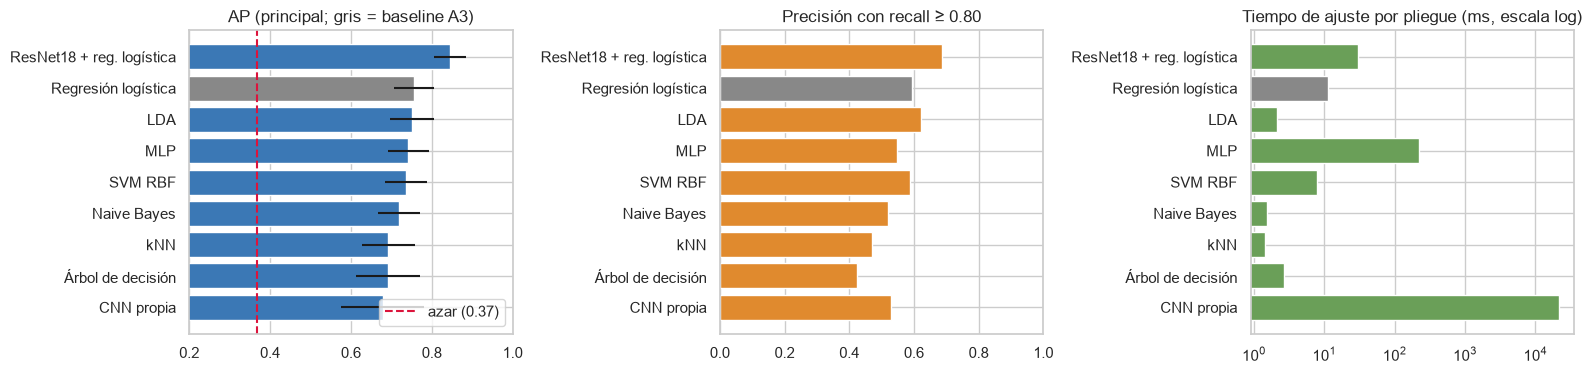

In [6]:
v = comp.drop(index=SIN_APRENDER).sort_values("AP")
col = ["#888888" if m == BASELINE else "#3b78b5" for m in v.index]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.9))
ax[0].barh(v.index, v.AP, xerr=v.AP_desv, color=col); ax[0].axvline(PREV, color="crimson", ls="--", label=f"azar ({PREV:.2f})")
ax[0].set_xlim(0.2, 1); ax[0].set_title("AP (principal; gris = baseline A3)"); ax[0].legend(loc="lower right")
ax[1].barh(v.index, v["Prec@Rec80"], color=["#888888" if m == BASELINE else "#e08a2e" for m in v.index]); ax[1].set_xlim(0, 1); ax[1].set_title("Precisión con recall ≥ 0.80")
ax[2].barh(v.index, v.ajuste_ms, color=["#888888" if m == BASELINE else "#6a9f58" for m in v.index]); ax[2].set_xscale("log"); ax[2].set_title("Tiempo de ajuste por pliegue (ms, escala log)")
plt.tight_layout(); plt.show()

In [7]:
mej = comp.loc[ALTERNATIVOS].sort_values("AP", ascending=False); top, ult = mej.index[0], mej.index[-1]; b0 = comp.loc[BASELINE]
display(Markdown(
    f"- **Mejor alternativo por AP:** {top} ({mej.AP.iloc[0]:.3f} ± {mej.AP_desv.iloc[0]:.3f}); **peor:** {ult} ({mej.AP.iloc[-1]:.3f}). Baseline del Avance 3: {b0.AP:.3f} ± {b0.AP_desv:.3f}; sin aprendizaje: {comp.loc['Dummy (prior)', 'AP']:.3f}. "
    f"{'Ningún alternativo supera al baseline por más que su margen de error.' if mej.AP.iloc[0] - b0.AP < b0.AP_desv else 'El mejor alternativo supera al baseline por más que su margen de error.'}\n"
    f"- **Rango de la tabla:** {mej.AP.iloc[0] - mej.AP.iloc[-1]:.3f} de AP entre el primero y el último, frente a una desviación entre pliegues de ≈ {mej.AP_desv.mean():.3f}: "
    f"{'los modelos de la parte alta no se distinguen entre sí con claridad' if (mej.AP.iloc[0] - mej.AP.iloc[1]) < mej.AP_desv.mean() else 'el primero se separa del resto'}.\n"
    f"- **Tiempos:** el ajuste más lento es {mej.ajuste_ms.idxmax()} ({mej.ajuste_ms.max():.1f} ms) y el más rápido {mej.ajuste_ms.idxmin()} ({mej.ajuste_ms.min():.2f} ms); "
    f"el más lento en predecir toma {mej.pred_ms_por_fruto.max():.2f} ms por fruto, cifra que debe contrastarse con el tiempo de ciclo de la línea (a confirmar con SOLID)."))

- **Mejor alternativo por AP:** ResNet18 + reg. logística (0.845 ± 0.040); **peor:** CNN propia (0.678). Baseline del Avance 3: 0.756 ± 0.048; sin aprendizaje: 0.358. El mejor alternativo supera al baseline por más que su margen de error.
- **Rango de la tabla:** 0.167 de AP entre el primero y el último, frente a una desviación entre pliegues de ≈ 0.062: el primero se separa del resto.
- **Tiempos:** el ajuste más lento es CNN propia (21825.3 ms) y el más rápido kNN (1.44 ms); el más lento en predecir toma 14.18 ms por fruto, cifra que debe contrastarse con el tiempo de ciclo de la línea (a confirmar con SOLID).

## 4. Selección de los dos mejores
**Regla (fijada antes de mirar el ajuste):** entre los **seis modelos alternativos** (el baseline es la referencia y no compite), los dos con mayor **AP** en validación cruzada. Si el segundo y el tercero quedan empatados (diferencia menor que la desviación entre pliegues), se desempata con la precisión a recall ≥ 0.80 y, después, con el menor tiempo de ajuste. Así la selección no depende de una sola cifra ruidosa.

In [8]:
mej = comp.loc[ALTERNATIVOS].copy()
ordenado = mej.sort_values(["AP", "Prec@Rec80", "ajuste_ms"], ascending=[False, False, True])
tol = float(mej.AP_desv.mean())
segundo_y_tercero = ordenado.iloc[1:3]
if segundo_y_tercero.AP.iloc[0] - segundo_y_tercero.AP.iloc[1] < tol:                # empate técnico por el 2.º lugar
    desempate = segundo_y_tercero.sort_values(["Prec@Rec80", "ajuste_ms"], ascending=[False, True])
    DOS = [ordenado.index[0], desempate.index[0]]
else:
    DOS = list(ordenado.index[:2])
display(Markdown(f"**Modelos seleccionados para ajuste:** `{DOS[0]}` (AP = {comp.loc[DOS[0], 'AP']:.3f}) y `{DOS[1]}` (AP = {comp.loc[DOS[1], 'AP']:.3f}). "
                 f"Tolerancia de empate = {tol:.3f} (desviación media entre pliegues)."))
display(mej.loc[ordenado.index, ["AP", "AP_desv", "Prec@Rec80", "ROC_AUC", "ajuste_ms"]].round(3).assign(seleccionado=lambda d: d.index.isin(DOS)))
print(f"Baseline (referencia, no compite): AP = {comp.loc[BASELINE, 'AP']:.3f}")

**Modelos seleccionados para ajuste:** `ResNet18 + reg. logística` (AP = 0.845) y `LDA` (AP = 0.751). Tolerancia de empate = 0.062 (desviación media entre pliegues).

,AP,AP_desv,Prec@Rec80,ROC_AUC,ajuste_ms,seleccionado
modelo,,,,,,
ResNet18 + reg. logística,0.845,0.040,0.688,0.873,29.682,True
LDA,0.751,0.055,0.623,0.820,2.151,True
MLP,0.742,0.050,0.549,0.803,224.235,False
SVM RBF,0.737,0.053,0.589,0.796,7.885,False
Naive Bayes,0.719,0.052,0.520,0.785,1.504,False
kNN,0.693,0.066,0.470,0.781,1.442,False
Árbol de decisión,0.691,0.079,0.423,0.736,2.646,False
CNN propia,0.678,0.103,0.529,0.764,21825.267,False


Baseline (referencia, no compite): AP = 0.756


## 5. Ajuste fino de los dos mejores

### 5.1 Diseño de la búsqueda
- **Método:** búsqueda aleatoria (`RandomizedSearchCV`) sobre distribuciones (log-uniformes para escalas como `C`, `gamma`, `alpha` y tasa de aprendizaje), con **120 configuraciones por modelo** (60 para el MLP, que es más costoso). Una búsqueda aleatoria explora mejor un espacio de varias dimensiones que una rejilla del mismo costo (Bergstra y Bengio, 2012; Géron, 2022, cap. 2, *Fine-Tune Your Model*).
- **Criterio:** AP medio en CV agrupada **5×2** sobre *train* (10 ajustes por configuración).
- **Qué se ajusta:** hiperparámetros de regularización, de kernel/arquitectura y de optimización según el modelo (tabla siguiente). El espacio está definido para los seis alternativos; por ejemplo, el del MLP incluye tamaño y número de capas, **función de activación**, regularización L2 y **tasa de aprendizaje**, y se usaría si ese modelo quedara entre los dos mejores.
- **Honestidad de la estimación:** la mejor configuración de una búsqueda tiene un AP *optimista* porque se eligió sobre los mismos pliegues. Por eso se añade una **validación cruzada anidada** (5.3) —la búsqueda se repite dentro de cada pliegue externo— y una comprobación en el conjunto de **validación**, que no participó en la búsqueda.

In [9]:
ESPACIOS = {
    "Regresión logística": {"C": loguniform(1e-3, 1e2), "penalty": ["l1", "l2"], "class_weight": [None, "balanced"], "solver": ["liblinear"]},
    "LDA":                 {"solver": ["lsqr"], "shrinkage": uniform(0.0, 1.0)},
    "Naive Bayes":         {"var_smoothing": loguniform(1e-9, 1e-1)},
    "kNN":                 {"n_neighbors": randint(3, 60), "weights": ["uniform", "distance"], "p": [1, 2]},
    "Árbol de decisión":   {"max_depth": randint(2, 9), "min_samples_leaf": randint(1, 25), "min_samples_split": randint(2, 30),
                            "ccp_alpha": loguniform(1e-4, 1e-1), "criterion": ["gini", "entropy"], "class_weight": [None, "balanced"]},
    "SVM RBF":             {"C": loguniform(1e-2, 1e3), "gamma": loguniform(1e-4, 1e0), "class_weight": [None, "balanced"]},
    "ResNet18 + reg. logística": {"pca__n_components": [8, 16, 32, 64, 128], "clf__C": loguniform(1e-4, 1e0), "clf__class_weight": [None, "balanced"]},
    "CNN propia":         {"base": [8, 16, 24], "dropout": uniform(0.1, 0.5), "activation": ["relu", "leaky_relu", "elu"],
                            "lr": loguniform(1e-4, 5e-3), "weight_decay": loguniform(1e-5, 1e-2)},
    "MLP":                 {"hidden_layer_sizes": [(8,), (16,), (32,), (64,), (16, 8), (32, 16), (64, 32)], "activation": ["relu", "tanh", "logistic"],
                            "alpha": loguniform(1e-4, 1e0), "learning_rate_init": loguniform(1e-4, 1e-1)},
}
N_ITER = {m: (60 if m == "MLP" else 20 if m == "CNN propia" else 120) for m in ALTERNATIVOS}      # la CNN es mucho más costosa
es_img = lambda m: ESPACIO.get(m) == "img"
display(pd.DataFrame({"hiperparámetros explorados": {m: ", ".join(ESPACIOS[m]) for m in DOS},
                      "configuraciones": {m: N_ITER[m] for m in DOS}}))

,hiperparámetros explorados,configuraciones
ResNet18 + reg. logística,"pca__n_components, clf__C, clf__class_weight",120
LDA,"solver, shrinkage",120


In [10]:
SPLITS = [(tri, tei) for _, tri, tei in folds(ytr, gtr, reps=2)]          # 10 particiones agrupadas
BUSQ = {}
for m in DOS:
    t0 = time.perf_counter()
    spl = SPLITS[:5] if es_img(m) else SPLITS                                   # CNN: 5 particiones (1 repetición) para acotar el costo
    rs = RandomizedSearchCV(clone(MODELOS[m]), ESPACIOS[m], n_iter=N_ITER[m], scoring="average_precision", cv=spl,
                            random_state=SEED, n_jobs=(1 if es_img(m) else -1), refit=True, return_train_score=True).fit(ES(m)["tr"], ytr)
    BUSQ[m] = rs
    base_ap = comp.loc[m, "AP"]
    print(f"{m}: {N_ITER[m]} configuraciones × {len(spl)} particiones = {N_ITER[m] * len(spl)} ajustes en {time.perf_counter() - t0:.0f} s · "
          f"AP sin ajustar (5×3) = {base_ap:.3f} → mejor AP de la búsqueda = {rs.best_score_:.3f}")
    print("   mejores hiperparámetros:", {k: (round(float(v), 5) if isinstance(v, (np.floating, float)) else v) for k, v in rs.best_params_.items()})

ResNet18 + reg. logística: 120 configuraciones × 10 particiones = 1200 ajustes en 22 s · AP sin ajustar (5×3) = 0.845 → mejor AP de la búsqueda = 0.867
   mejores hiperparámetros: {'clf__C': 0.00758, 'clf__class_weight': 'balanced', 'pca__n_components': 128}


LDA: 120 configuraciones × 10 particiones = 1200 ajustes en 2 s · AP sin ajustar (5×3) = 0.751 → mejor AP de la búsqueda = 0.758
   mejores hiperparámetros: {'shrinkage': 0.07698, 'solver': 'lsqr'}


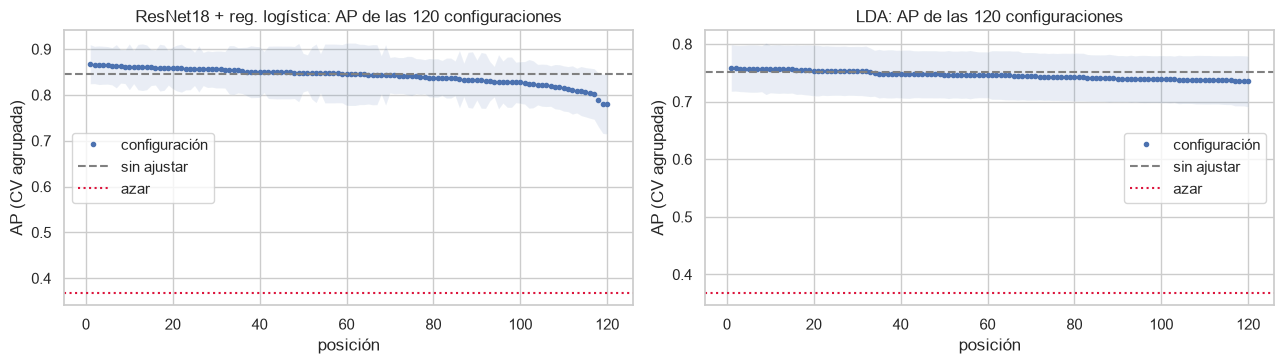


ResNet18 + reg. logística: 5 mejores configuraciones


,clf__C,clf__class_weight,pca__n_components,mean_test_score,std_test_score,mean_train_score,mean_fit_time
0,0.0076,balanced,128,0.8670,0.0426,0.9876,0.0494
1,0.0108,balanced,128,0.8654,0.0407,0.9928,0.0429
2,0.0176,None,128,0.8648,0.0422,0.9965,0.0407
3,0.0036,balanced,128,0.8647,0.0415,0.9711,0.0455
4,0.0035,balanced,128,0.8646,0.0411,0.9704,0.0460



LDA: 5 mejores configuraciones


,shrinkage,solver,mean_test_score,std_test_score,mean_train_score,mean_fit_time
0,0.0770,lsqr,0.7584,0.0405,0.7919,0.0046
1,0.0465,lsqr,0.7580,0.0398,0.7958,0.0040
2,0.0746,lsqr,0.7574,0.0401,0.7923,0.0039
3,0.0452,lsqr,0.7574,0.0404,0.7959,0.0038
4,0.0651,lsqr,0.7573,0.0410,0.7936,0.0037


In [11]:
# Evidencia de profundidad de la búsqueda: distribución del AP de todas las configuraciones y las 5 mejores
fig, ax = plt.subplots(1, len(DOS), figsize=(6.5 * len(DOS), 3.8))
ax = np.atleast_1d(ax)
for a, m in zip(ax, DOS):
    r = pd.DataFrame(BUSQ[m].cv_results_).sort_values("mean_test_score", ascending=False).reset_index(drop=True)
    a.plot(r.index + 1, r.mean_test_score, "o", ms=3, label="configuración")
    a.fill_between(r.index + 1, r.mean_test_score - r.std_test_score, r.mean_test_score + r.std_test_score, alpha=.12)
    a.axhline(comp.loc[m, "AP"], color="gray", ls="--", label="sin ajustar"); a.axhline(PREV, color="crimson", ls=":", label="azar")
    a.set_title(f"{m}: AP de las {len(r)} configuraciones"); a.set_xlabel("posición"); a.set_ylabel("AP (CV agrupada)"); a.legend()
plt.tight_layout(); plt.show()
for m in DOS:
    r = pd.DataFrame(BUSQ[m].cv_results_).sort_values("mean_test_score", ascending=False).head(5)
    cols = [c for c in r.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "mean_train_score", "mean_fit_time"]
    print(f"\n{m}: 5 mejores configuraciones"); display(r[cols].rename(columns=lambda c: c.replace("param_", "")).round(4).reset_index(drop=True))

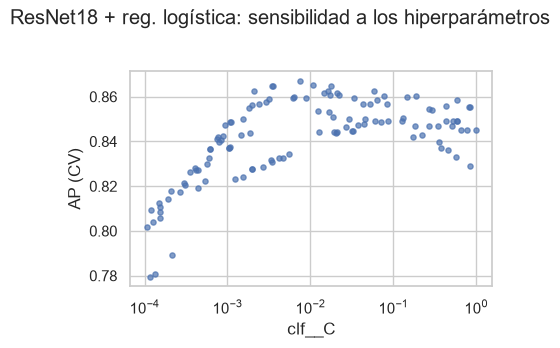

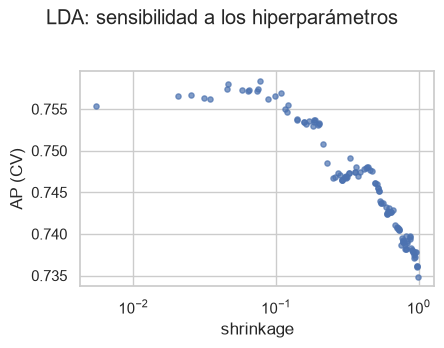

In [12]:
# Sensibilidad: cómo cambia el AP con cada hiperparámetro numérico (escala log cuando abarca varias décadas)
for m in DOS:
    r = pd.DataFrame(BUSQ[m].cv_results_)
    num = [c for c in r.columns if c.startswith("param_") and pd.api.types.is_numeric_dtype(pd.to_numeric(r[c], errors="coerce")) and pd.to_numeric(r[c], errors="coerce").nunique() > 6]
    if not num: continue
    fig, ax = plt.subplots(1, len(num), figsize=(4.6 * len(num), 3.4)); ax = np.atleast_1d(ax)
    for a, c in zip(ax, num):
        x = pd.to_numeric(r[c]); a.scatter(x, r.mean_test_score, s=14, alpha=.7)
        if x.min() > 0 and x.max() / x.min() > 50: a.set_xscale("log")
        a.set_xlabel(c.replace("param_", "")); a.set_ylabel("AP (CV)")
    fig.suptitle(f"{m}: sensibilidad a los hiperparámetros", y=1.02); plt.tight_layout(); plt.show()

### 5.2 Efecto del ajuste en entrenamiento, CV y validación
Se compara cada modelo **sin ajustar** y **ajustado** en tres lugares: AP en CV 5×3 de *train* (misma validación cruzada de la sección 3), AP en el conjunto de **validación** (no participó en la búsqueda) y la brecha entre el AP de entrenamiento y el de CV como señal de sobreajuste.

In [13]:
filas = []
for m in DOS:
    for etiqueta, est in [("sin ajustar", clone(MODELOS[m])), ("ajustado", clone(BUSQ[m].best_estimator_))]:
        res, _ = cv_modelo(est, ES(m)["tr"], ytr, gtr)
        fit = clone(est).fit(ES(m)["tr"], ytr)
        p_tr, p_va = fit.predict_proba(ES(m)["tr"])[:, 1], fit.predict_proba(ES(m)["va"])[:, 1]
        filas.append({"modelo": m, "versión": etiqueta, "AP_train": average_precision_score(ytr, p_tr), "AP_CV": res["AP"], "AP_CV_desv": res["AP_desv"],
                      "AP_val": average_precision_score(yva, p_va), "ROC_AUC_val": roc_auc_score(yva, p_va), "Prec@Rec80_val": prec_at_rec(yva, p_va),
                      "brecha_train−CV": average_precision_score(ytr, p_tr) - res["AP"], "ajuste_ms": res["ajuste_ms"]})
efecto = pd.DataFrame(filas).set_index(["modelo", "versión"])
display(efecto.round(3))

AP_train  AP_CV  AP_CV_desv  AP_val  ROC_AUC_val  Prec@Rec80_val  brecha_train−CV  ajuste_ms
modelo                    versión                                                                                                  
ResNet18 + reg. logística sin ajustar     0.984  0.845       0.040   0.627        0.748           0.591            0.139     28.448
                          ajustado        0.981  0.863       0.047   0.567        0.716           0.542            0.118     33.231
LDA                       sin ajustar     0.803  0.751       0.055   0.548        0.601           0.382            0.052      1.527
                          ajustado        0.785  0.749       0.051   0.524        0.547           0.372            0.036      1.806

### 5.3 Validación cruzada anidada (estimación sin optimismo)
Para cada pliegue externo (5 pliegues agrupados) la búsqueda se repite **solo con los datos de entrenamiento de ese pliegue** (30 configuraciones —6 para la CNN—, CV agrupada interna de 3 pliegues) y el modelo resultante se evalúa en el pliegue externo, que la búsqueda nunca vio. Se compara con el modelo sin ajustar en los **mismos** pliegues externos. Esta es la estimación que se usa para decidir si el ajuste realmente mejora y para comparar a los dos finalistas.

In [14]:
EXT = [(tri, tei) for _, tri, tei in folds(ytr, gtr, reps=1, seed=SEED + 100)]
filas, oof_nest = [], {}
for m in DOS:
    t0 = time.perf_counter(); ap_aj, ap_def = [], []; p_aj = np.zeros(len(ytr)); p_def = np.zeros(len(ytr))
    for tri, tei in EXT:
        rs = RandomizedSearchCV(clone(MODELOS[m]), ESPACIOS[m], n_iter=(6 if es_img(m) else 30), scoring="average_precision",
                                cv=StratifiedGroupKFold(3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=(1 if es_img(m) else -1), refit=True
                                ).fit(ES(m)["tr"].iloc[tri], ytr[tri], groups=gtr[tri])
        p_aj[tei] = rs.predict_proba(ES(m)["tr"].iloc[tei])[:, 1]
        p_def[tei] = clone(MODELOS[m]).fit(ES(m)["tr"].iloc[tri], ytr[tri]).predict_proba(ES(m)["tr"].iloc[tei])[:, 1]
        ap_aj.append(average_precision_score(ytr[tei], p_aj[tei])); ap_def.append(average_precision_score(ytr[tei], p_def[tei]))
    oof_nest[m] = p_aj
    d = np.array(ap_aj) - np.array(ap_def)
    filas.append({"modelo": m, "AP_anidado_ajustado": np.mean(ap_aj), "AP_anidado_desv": np.std(ap_aj), "AP_sin_ajustar_mismos_pliegues": np.mean(ap_def),
                  "mejora_media": d.mean(), "mejora_desv": d.std(), "pliegues_que_mejoran": int((d > 0).sum()),
                  "Prec@Rec80_anidado": prec_at_rec(ytr, p_aj), "ROC_AUC_anidado": roc_auc_score(ytr, p_aj), "t_s": time.perf_counter() - t0})
nest = pd.DataFrame(filas).set_index("modelo")
display(nest.round(3))

,AP_anidado_ajustado,AP_anidado_desv,AP_sin_ajustar_mismos_pliegues,mejora_media,mejora_desv,pliegues_que_mejoran,Prec@Rec80_anidado,ROC_AUC_anidado,t_s
modelo,,,,,,,,,
ResNet18 + reg. logística,0.863,0.062,0.845,0.018,0.010,5,0.673,0.867,2.693
LDA,0.739,0.110,0.763,-0.024,0.036,2,0.484,0.744,0.757


In [15]:
for m in DOS:
    n, e = nest.loc[m], efecto.loc[(m, "ajustado")]
    display(Markdown(
        f"- **{m}.** AP de la búsqueda (optimista) = {BUSQ[m].best_score_:.3f}; AP anidado (honesto) = **{n.AP_anidado_ajustado:.3f} ± {n.AP_anidado_desv:.3f}** frente a "
        f"{n.AP_sin_ajustar_mismos_pliegues:.3f} sin ajustar (mejora {n.mejora_media:+.3f}, en {int(n.pliegues_que_mejoran)} de {len(EXT)} pliegues). "
        f"En validación: AP = {e.AP_val:.3f}. Optimismo de la búsqueda = {BUSQ[m].best_score_ - n.AP_anidado_ajustado:+.3f}."))

- **ResNet18 + reg. logística.** AP de la búsqueda (optimista) = 0.867; AP anidado (honesto) = **0.863 ± 0.062** frente a 0.845 sin ajustar (mejora +0.018, en 5 de 5 pliegues). En validación: AP = 0.567. Optimismo de la búsqueda = +0.005.

- **LDA.** AP de la búsqueda (optimista) = 0.758; AP anidado (honesto) = **0.739 ± 0.110** frente a 0.763 sin ajustar (mejora -0.024, en 2 de 5 pliegues). En validación: AP = 0.524. Optimismo de la búsqueda = +0.020.

## 6. Elección del modelo individual final

### 6.1 Criterios
La decisión no se reduce a la métrica principal. Se consideran, en este orden:

1. **Desempeño honesto** (AP anidado) y **precisión con recall ≥ 0.80**, que es lo que le importa al negocio.
2. **Estabilidad:** si la diferencia de AP entre los dos finalistas es menor que su desviación entre pliegues, hay **empate técnico** y deciden los criterios siguientes.
3. **Interpretabilidad:** SOLID debe poder explicar por qué se expulsa un fruto y qué variable de proceso vigilar.
4. **Costo computacional y de mantenimiento:** tiempo de ajuste y de predicción, número de hiperparámetros, sensibilidad a la escala y a la deriva de la iluminación.
5. **Riesgo de sobreajuste:** brecha entre entrenamiento y CV.

| Modelo | Interpretabilidad | Hiperparámetros a mantener | Sensible a la escala | Probabilidades |
|---|---|---|---|---|
| Regresión logística | Alta (coeficientes con signo) | 1–2 | Sí (ya estandarizado) | Calibradas razonablemente |
| LDA | Alta (dirección discriminante) | 1 | Sí | Razonables bajo normalidad |
| Naive Bayes | Media | 1 | No | Sobreconfiadas |
| Árbol de decisión | Alta si es poco profundo | 4–6 | No | Escalonadas |
| kNN | Baja (guarda todos los datos) | 3 | Sí | Poco finas |
| SVM RBF | Baja | 2–3 | Sí | Vía Platt (costo extra) |
| MLP | Baja | 5–6 | Sí | Pueden estar mal calibradas |
| ResNet18 + regresión logística | Baja (embeddings opacos) | 2–3 | Sí | Calibradas razonablemente; requiere el *backbone* en producción |
| CNN propia | Baja | 5–6 | Sí (imagen) | Pueden estar mal calibradas; requiere GPU/CPU y reentrenar con cada sesión de captura |

In [16]:
INTERP = {"Regresión logística": 3, "LDA": 3, "Árbol de decisión": 3, "Naive Bayes": 2, "kNN": 1, "SVM RBF": 1, "MLP": 1, "ResNet18 + reg. logística": 1, "CNN propia": 1}
ficha = pd.DataFrame({
    "AP_anidado": nest.AP_anidado_ajustado, "desv": nest.AP_anidado_desv, "Prec@Rec80_anidado": nest["Prec@Rec80_anidado"],
    "AP_val": [efecto.loc[(m, "ajustado"), "AP_val"] for m in DOS], "brecha_train−CV": [efecto.loc[(m, "ajustado"), "brecha_train−CV"] for m in DOS],
    "ajuste_ms": [efecto.loc[(m, "ajustado"), "ajuste_ms"] for m in DOS], "pred_ms": [comp.loc[m, "pred_ms_por_fruto"] for m in DOS], "interpretabilidad(1-3)": [INTERP[m] for m in DOS]}, index=DOS)
display(ficha.round(3))

a, b = DOS
dif = ficha.loc[a, "AP_anidado"] - ficha.loc[b, "AP_anidado"]
tol_fin = min(ficha.loc[a, "desv"], ficha.loc[b, "desv"])
if abs(dif) <= tol_fin:                                              # empate técnico → interpretabilidad, luego Prec@Rec80, luego costo
    orden = ficha.sort_values(["interpretabilidad(1-3)", "Prec@Rec80_anidado", "ajuste_ms"], ascending=[False, False, True])
    FINAL_NOM, motivo = orden.index[0], "empate técnico en AP"
else:
    FINAL_NOM, motivo = ficha.AP_anidado.idxmax(), "mayor AP anidado fuera del margen de error"
OTRO = b if FINAL_NOM == a else a
display(Markdown(f"**Modelo individual final: `{FINAL_NOM}`** ({motivo}). Diferencia de AP anidado entre los finalistas: {dif:+.3f} (margen de error ≈ {tol_fin:.3f})."))

,AP_anidado,desv,Prec@Rec80_anidado,AP_val,brecha_train−CV,ajuste_ms,pred_ms,interpretabilidad(1-3)
ResNet18 + reg. logística,0.863,0.062,0.673,0.567,0.118,33.231,14.176,1
LDA,0.739,0.110,0.484,0.524,0.036,1.806,0.019,3


**Modelo individual final: `ResNet18 + reg. logística`** (mayor AP anidado fuera del margen de error). Diferencia de AP anidado entre los finalistas: +0.124 (margen de error ≈ 0.062).

In [17]:
F, O = ficha.loc[FINAL_NOM], ficha.loc[OTRO]
argumentos = [
    f"**Desempeño.** AP anidado {F.AP_anidado:.3f} ± {F.desv:.3f} frente a {O.AP_anidado:.3f} ± {O.desv:.3f} de {OTRO}; precisión con recall ≥ 0.80 de {F['Prec@Rec80_anidado']:.2f} frente a {O['Prec@Rec80_anidado']:.2f}. "
    + ("La diferencia queda dentro del margen de error, por lo que no hay base estadística para preferir uno solo por la métrica." if abs(dif) <= tol_fin else "La diferencia supera el margen de error."),
    f"**Interpretabilidad.** {FINAL_NOM} tiene nivel {int(F['interpretabilidad(1-3)'])} de 3 contra {int(O['interpretabilidad(1-3)'])} de {OTRO}. "
    + ("Permite explicar cada decisión (coeficientes, reglas o direcciones discriminantes) y vigilar variables concretas de la línea." if F["interpretabilidad(1-3)"] >= 3 else "Es una caja negra relativa: la explicación de cada decisión requiere herramientas adicionales."),
    f"**Costo.** Ajuste de {F.ajuste_ms:.1f} ms por pliegue y predicción de {F.pred_ms:.2f} ms por fruto ({FINAL_NOM}) frente a {O.ajuste_ms:.1f} ms y {O.pred_ms:.2f} ms ({OTRO}). "
    + ("Además requiere la red preentrenada en producción (≈ 45 MB, ejecutable en CPU). " if ESPACIO.get(FINAL_NOM) == "emb" else "")
    + "Ambos son compatibles con un ciclo de línea de decenas de milisegundos o más (a confirmar con SOLID).",
    f"**Sobreajuste.** Brecha entre AP de entrenamiento y de CV: {F['brecha_train−CV']:.3f} ({FINAL_NOM}) frente a {O['brecha_train−CV']:.3f} ({OTRO}). "
    + ("Ninguno muestra sobreajuste marcado." if max(F['brecha_train−CV'], O['brecha_train−CV']) < 0.15 else "Al menos uno de los dos muestra una brecha que conviene vigilar."),
    f"**Validación independiente.** AP en el conjunto de validación (que no participó en la búsqueda): {F.AP_val:.3f} ({FINAL_NOM}) y {O.AP_val:.3f} ({OTRO}). "
    f"Con solo {len(yva)} frutos esta cifra es ruidosa y se usa como comprobación, no como criterio de selección.",
    "**Trade-off.** " + (f"Se acepta menor interpretabilidad a cambio de un AP anidado mayor en {F.AP_anidado - O.AP_anidado:+.3f} y una mejor precisión con recall ≥ 0.80; como mitigación, {OTRO} (interpretable) queda como modelo de respaldo y de explicación, y la decisión del modelo final puede acompañarse de mapas de activación (p. ej. Grad-CAM)."
                         if F["interpretabilidad(1-3)"] < O["interpretabilidad(1-3)"] else "La elección no sacrifica interpretabilidad respecto al otro finalista."),
]
display(Markdown("\n".join(f"{i + 1}. {t}" for i, t in enumerate(argumentos))))

1. **Desempeño.** AP anidado 0.863 ± 0.062 frente a 0.739 ± 0.110 de LDA; precisión con recall ≥ 0.80 de 0.67 frente a 0.48. La diferencia supera el margen de error.
2. **Interpretabilidad.** ResNet18 + reg. logística tiene nivel 1 de 3 contra 3 de LDA. Es una caja negra relativa: la explicación de cada decisión requiere herramientas adicionales.
3. **Costo.** Ajuste de 33.2 ms por pliegue y predicción de 14.18 ms por fruto (ResNet18 + reg. logística) frente a 1.8 ms y 0.02 ms (LDA). Además requiere la red preentrenada en producción (≈ 45 MB, ejecutable en CPU). Ambos son compatibles con un ciclo de línea de decenas de milisegundos o más (a confirmar con SOLID).
4. **Sobreajuste.** Brecha entre AP de entrenamiento y de CV: 0.118 (ResNet18 + reg. logística) frente a 0.036 (LDA). Ninguno muestra sobreajuste marcado.
5. **Validación independiente.** AP en el conjunto de validación (que no participó en la búsqueda): 0.567 (ResNet18 + reg. logística) y 0.524 (LDA). Con solo 45 frutos esta cifra es ruidosa y se usa como comprobación, no como criterio de selección.
6. **Trade-off.** Se acepta menor interpretabilidad a cambio de un AP anidado mayor en +0.124 y una mejor precisión con recall ≥ 0.80; como mitigación, LDA (interpretable) queda como modelo de respaldo y de explicación, y la decisión del modelo final puede acompañarse de mapas de activación (p. ej. Grad-CAM).

### 6.2 Control de fuga por sesión de captura
Un modelo de imagen puede acertar por razones equivocadas: si los frutos buenos y malos se fotografiaron en sesiones distintas, la red podría reconocer el **fondo o la iluminación** en lugar del defecto (riesgo señalado desde el Avance 2). Se repite la evaluación de la ResNet18 con tres entradas: el recorte completo, **solo el fruto** (fondo en gris) y **solo el fondo** (fruto tapado). Si el fondo por sí solo predijera la clase, habría fuga.

In [18]:
if HAY_IMG:
    def emb_modo(modo):
        def rec(r):
            im = np.asarray(Image.open(IMG_ROOT / "output" / f"{r.crop_id}.png").convert("RGB")).copy(); h, w = im.shape[:2]
            yy, xx = np.ogrid[:h, :w]; d = np.hypot(xx - r.cx, yy - r.cy)
            if modo == "fondo": im[d <= r.radio * 1.10] = 128                    # tapa el fruto
            else:               im[d > r.radio * 1.05] = 128                     # deja solo el fruto
            R = int(round(r.radio)) + 20; cx, cy = int(round(r.cx)), int(round(r.cy))
            c = Image.fromarray(im).crop((max(0, cx - R), max(0, cy - R), min(w, cx + R), min(h, cy + R)))
            return np.asarray(c.resize((224, 224), Image.BILINEAR))
        z = np.stack([rec(r) for r in ALL.itertuples()]); z = (torch.from_numpy(z).permute(0, 3, 1, 2).float() / 255 - mu) / sd
        with torch.no_grad(): return torch.cat([red(z[i:i + 64]) for i in range(0, len(z), 64)]).numpy()
    filas = []
    for modo, E_ in [("recorte completo", EMB), ("solo el fruto", emb_modo("fruto")), ("solo el fondo (fruto tapado)", emb_modo("fondo"))]:
        F_ = pd.DataFrame(E_[:len(TR)], columns=ESPACIOS_X["emb"]["tr"].columns)
        r_, _ = cv_modelo(clone(MODELOS["ResNet18 + reg. logística"]), F_, ytr, gtr)
        filas.append({"entrada": modo, "AP": r_["AP"], "ROC_AUC": r_["ROC_AUC"], "AP_desv": r_["AP_desv"]})
    ctrl = pd.DataFrame(filas).set_index("entrada"); display(ctrl.round(3))
    fondo, fruto, compl = ctrl.iloc[2], ctrl.iloc[1], ctrl.iloc[0]
    display(Markdown(
        f"- **Solo el fruto:** AP = {fruto.AP:.3f} frente a {compl.AP:.3f} con el recorte completo: {'la señal está en el fruto' if compl.AP - fruto.AP < 0.05 else 'parte de la señal viene del entorno del fruto'}.\n"
        f"- **Solo el fondo:** AP = {fondo.AP:.3f} (ROC-AUC {fondo.ROC_AUC:.2f}) frente a {PREV:.3f} del azar: "
        f"{'el fondo casi no predice la clase, de modo que no hay evidencia de que la red esté reconociendo la sesión de captura.' if fondo.AP - PREV < 0.10 else 'el fondo por sí solo predice la clase: hay riesgo de fuga por sesión de captura y los resultados de imagen deben tomarse con reserva.'}\n"
        f"- **Alcance:** la agrupación por bloques asume que la numeración de los archivos respeta el orden de captura; conviene validar con fotos de otra sesión antes de producción."))
else:
    print("Sin imágenes: control omitido.")

,AP,ROC_AUC,AP_desv
entrada,,,
recorte completo,0.845,0.873,0.040
solo el fruto,0.845,0.876,0.045
solo el fondo (fruto tapado),0.439,0.591,0.076


- **Solo el fruto:** AP = 0.845 frente a 0.845 con el recorte completo: la señal está en el fruto.
- **Solo el fondo:** AP = 0.439 (ROC-AUC 0.59) frente a 0.368 del azar: el fondo casi no predice la clase, de modo que no hay evidencia de que la red esté reconociendo la sesión de captura.
- **Alcance:** la agrupación por bloques asume que la numeración de los archivos respeta el orden de captura; conviene validar con fotos de otra sesión antes de producción.

## 7. Evaluación del modelo final en prueba (una sola vez)
Se fija el umbral con la **misma regla del Avance 3** —el umbral más alto con recall ≥ 0.80 en predicciones fuera de pliegue de *train*— y se reajusta el modelo con **train + validación**. Se evalúa **una única vez** en prueba junto con el baseline del Avance 3 (regresión logística con su umbral original), con IC 95 % por *bootstrap* de bloques. Los criterios son los de ese avance: C1 (AP mejor que el azar, con límite inferior del IC sobre la prevalencia), C2 (recall ≥ 0.80) y C3 (precisión ≥ 0.60).

In [19]:
MEJOR = clone(BUSQ[FINAL_NOM].best_estimator_)
# Umbral con predicciones fuera de pliegue de train (5 repeticiones), sin mirar validación ni prueba
_, oof5 = cv_modelo(MEJOR, ES(FINAL_NOM)["tr"], ytr, gtr, reps=5)
pr_, rc_, th_ = precision_recall_curve(np.tile(ytr, 5), oof5.ravel())
U = float(th_[rc_[:-1] >= REC_OBJ][-1])
print(f"Umbral del modelo final (mayor umbral con recall OOF ≥ {REC_OBJ}): {U:.3f}")

def boot_grupos(g, B, rng):
    u = np.unique(g); idx = {k: np.where(g == k)[0] for k in u}
    for _ in range(B): yield np.concatenate([idx[k] for k in rng.choice(u, len(u), replace=True)])

def evaluar(modelo, umbral, nombre, esp):
    f = clone(modelo).fit(esp["dev"], ydev); p = f.predict_proba(esp["te"])[:, 1]
    m = metricas(yte, p, umbral)
    bs = pd.DataFrame([metricas(yte[ix], p[ix], umbral) for ix in boot_grupos(gte, 1000, np.random.default_rng(SEED)) if yte[ix].min() != yte[ix].max()])
    ic = bs.quantile([.025, .975]).T.rename(columns={.025: "ic_inf", .975: "ic_sup"})
    return f, p, pd.DataFrame({nombre: pd.Series(m)}).join(ic.add_prefix(nombre + "_"))

base = LogisticRegression(C=C_BASE, class_weight="balanced", max_iter=5000)
f_fin, p_fin, r_fin = evaluar(MEJOR, U, "final", ES(FINAL_NOM))
f_base, p_base, r_base = evaluar(base, U_BASE, "baseline_A3", ESPACIOS_X["tab"])
res = r_fin.join(r_base)
orden = ["AP", "ROC_AUC", "Prec@Rec80", "recall_malo", "precision_malo", "F2", "bal_acc", "MCC", "accuracy"]
display(res.loc[orden].round(3))

Umbral del modelo final (mayor umbral con recall OOF ≥ 0.8): 0.412


,final,final_ic_inf,final_ic_sup,baseline_A3,baseline_A3_ic_inf,baseline_A3_ic_sup
AP,0.875,0.729,0.974,0.729,0.480,0.915
ROC_AUC,0.893,0.802,0.983,0.782,0.631,0.928
Prec@Rec80,0.727,0.516,1.000,0.593,0.394,0.870
recall_malo,0.850,0.737,1.000,0.850,0.600,1.000
precision_malo,0.708,0.565,0.857,0.586,0.361,0.800
F2,0.817,0.714,0.926,0.780,0.569,0.935
bal_acc,0.808,0.693,0.917,0.725,0.597,0.875
MCC,0.605,0.385,0.802,0.447,0.186,0.741
accuracy,0.800,0.687,0.902,0.700,0.556,0.857


,final,baseline_A3,cumple (final)
criterio,,,
C1. AP > azar (IC inf. > prevalencia),AP = 0.875 (IC 0.73–0.97) vs azar 0.400,AP = 0.729,Sí
C2. Recall(malo) ≥ 0.80,0.850,0.850,Sí
C3. Precisión(malo) ≥ 0.60,0.708,0.586,Sí


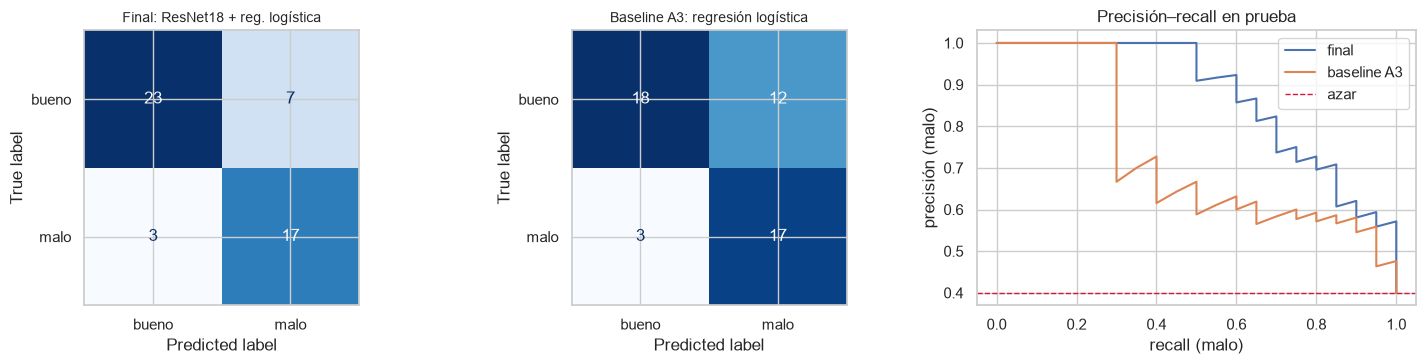

In [20]:
c1 = bool(res.loc["AP", "final_ic_inf"] > yte.mean()); c2 = bool(res.loc["recall_malo", "final"] >= REC_OBJ); c3 = bool(res.loc["precision_malo", "final"] >= 0.60)
display(pd.DataFrame({"criterio": ["C1. AP > azar (IC inf. > prevalencia)", "C2. Recall(malo) ≥ 0.80", "C3. Precisión(malo) ≥ 0.60"],
    "final": [f"AP = {res.loc['AP','final']:.3f} (IC {res.loc['AP','final_ic_inf']:.2f}–{res.loc['AP','final_ic_sup']:.2f}) vs azar {yte.mean():.3f}",
              f"{res.loc['recall_malo','final']:.3f}", f"{res.loc['precision_malo','final']:.3f}"],
    "baseline_A3": [f"AP = {res.loc['AP','baseline_A3']:.3f}", f"{res.loc['recall_malo','baseline_A3']:.3f}", f"{res.loc['precision_malo','baseline_A3']:.3f}"],
    "cumple (final)": ["Sí" if c1 else "No", "Sí" if c2 else "No", "Sí" if c3 else "No"]}).set_index("criterio"))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (nom, p, u) in zip(ax[:2], [(f"Final: {FINAL_NOM}", p_fin, U), ("Baseline A3: regresión logística", p_base, U_BASE)]):
    ConfusionMatrixDisplay(confusion_matrix(yte, (p >= u).astype(int)), display_labels=["bueno", "malo"]).plot(ax=a, colorbar=False, cmap="Blues"); a.set_title(nom, fontsize=10)
for nom, p in [("final", p_fin), ("baseline A3", p_base)]:
    pt, rt, _ = precision_recall_curve(yte, p); ax[2].plot(rt, pt, label=nom)
ax[2].axhline(yte.mean(), color="crimson", ls="--", lw=1, label="azar"); ax[2].set_xlabel("recall (malo)"); ax[2].set_ylabel("precisión (malo)"); ax[2].set_title("Precisión–recall en prueba"); ax[2].legend()
plt.tight_layout(); plt.show()

## 8. Resumen y conclusiones

In [21]:
mej = comp.loc[ALTERNATIVOS].sort_values("AP", ascending=False); b0 = comp.loc[BASELINE]
PARAMS = {k: (round(float(v), 4) if isinstance(v, (np.floating, float)) else v) for k, v in BUSQ[FINAL_NOM].best_params_.items()}
n_mod = len(mej); lc = ", ".join(f"{m} ({mej.loc[m, 'AP']:.3f})" for m in mej.index)
dif_ap_test = res.loc["AP", "final"] - res.loc["AP", "baseline_A3"]
tab_ap = comp.loc[[m for m in ALTERNATIVOS if ESPACIO.get(m, "tab") == "tab"], "AP"].max()
if ESPACIO.get(FINAL_NOM, "tab") != "tab":
    lectura = (f"El modelo final trabaja sobre {'los embeddings de una red preentrenada' if ESPACIO[FINAL_NOM] == 'emb' else 'los píxeles'}; su ventaja sobre el mejor modelo tabular ({comp.loc[FINAL_NOM, 'AP'] - tab_ap:+.3f} de AP en CV) "
               "parece provenir de la representación de entrada y no del algoritmo de la cabeza (una hipótesis coherente con que los embeddings conserven textura y estructura local que las 15 características globales resumen, pero que esta libreta no aísla). "
               "El control de la sección 6.2 indica si esa señal está en el fruto o en el fondo de la captura.")
else:
    lectura = "Las diferencias entre los modelos de la parte alta son menores que el margen de error: ningún algoritmo extrae información que los demás no tengan, y la elección se apoya en interpretabilidad y costo."
txt = f'''
**Comparativa.** Se evaluaron **{n_mod} modelos alternativos individuales** de familias distintas, el baseline del Avance 3 (AP {b0.AP:.3f}) y una referencia sin aprendizaje, con CV agrupada 5×3 y los mismos pliegues. Alternativos ordenados por AP: {lc}. \
Rango entre el primero y el último: {mej.AP.max() - mej.AP.min():.3f} de AP, frente a una desviación entre pliegues de ≈ {mej.AP_desv.mean():.3f}. La tabla incluye precisión con recall ≥ 0.80, ROC-AUC y tiempos de ajuste y predicción.

**Selección y ajuste.** Los dos mejores fueron **{DOS[0]}** y **{DOS[1]}**. Cada uno se ajustó con búsqueda aleatoria ({N_ITER[DOS[0]]} y {N_ITER[DOS[1]]} configuraciones, {len(SPLITS)} particiones agrupadas por configuración). \
Con validación cruzada anidada, el ajuste cambió el AP en {nest.loc[DOS[0], 'mejora_media']:+.3f} ({DOS[0]}) y {nest.loc[DOS[1], 'mejora_media']:+.3f} ({DOS[1]}); \
el optimismo de la búsqueda (AP de la búsqueda menos AP anidado) fue de {BUSQ[DOS[0]].best_score_ - nest.loc[DOS[0], 'AP_anidado_ajustado']:+.3f} y {BUSQ[DOS[1]].best_score_ - nest.loc[DOS[1], 'AP_anidado_ajustado']:+.3f}, \
razón por la cual la comparación final se hace con la estimación anidada. {'Ningún ajuste produjo una mejora distinguible en la estimación anidada: la superficie de AP es casi plana alrededor de los valores razonables y la mejora que muestra la búsqueda es, sobre todo, optimismo de selección.' if (nest.mejora_media <= 0.005).all() else 'Al menos un modelo mejora de forma consistente con el ajuste.'}

**Modelo final: {FINAL_NOM}** ({motivo}), con los hiperparámetros `{PARAMS}`.

**Prueba (n = {len(yte)}, una sola vez).** Con umbral {U:.2f}: recall = **{res.loc["recall_malo", "final"]:.2f}**, precisión = **{res.loc["precision_malo", "final"]:.2f}**, AP = {res.loc["AP", "final"]:.2f} \
(IC {res.loc["AP", "final_ic_inf"]:.2f}–{res.loc["AP", "final_ic_sup"]:.2f}); el baseline del Avance 3 obtuvo AP = {res.loc["AP", "baseline_A3"]:.2f} (diferencia {dif_ap_test:+.2f}). \
{"Los intervalos de confianza de ambos modelos se traslapan: la mejora coincide con la que se ve en validación cruzada, pero con ≈ 50 frutos de prueba no es concluyente por sí sola." if res.loc["AP", "final_ic_inf"] < res.loc["AP", "baseline_A3_ic_sup"] else "Los intervalos de confianza no se traslapan: la mejora es distinguible con esta muestra de prueba."}

**Lectura honesta.** {lectura} La muestra sigue siendo pequeña (≈ 250 recortes de entrenamiento y ≈ 50 de prueba) y la validación fija da valores más bajos que la validación cruzada en todos los modelos: las cifras deben leerse con sus intervalos.
'''
display(Markdown(txt))


**Comparativa.** Se evaluaron **8 modelos alternativos individuales** de familias distintas, el baseline del Avance 3 (AP 0.756) y una referencia sin aprendizaje, con CV agrupada 5×3 y los mismos pliegues. Alternativos ordenados por AP: ResNet18 + reg. logística (0.845), LDA (0.751), MLP (0.742), SVM RBF (0.737), Naive Bayes (0.719), kNN (0.693), Árbol de decisión (0.691), CNN propia (0.678). Rango entre el primero y el último: 0.167 de AP, frente a una desviación entre pliegues de ≈ 0.062. La tabla incluye precisión con recall ≥ 0.80, ROC-AUC y tiempos de ajuste y predicción.

**Selección y ajuste.** Los dos mejores fueron **ResNet18 + reg. logística** y **LDA**. Cada uno se ajustó con búsqueda aleatoria (120 y 120 configuraciones, 10 particiones agrupadas por configuración). Con validación cruzada anidada, el ajuste cambió el AP en +0.018 (ResNet18 + reg. logística) y -0.024 (LDA); el optimismo de la búsqueda (AP de la búsqueda menos AP anidado) fue de +0.005 y +0.020, razón por la cual la comparación final se hace con la estimación anidada. Al menos un modelo mejora de forma consistente con el ajuste.

**Modelo final: ResNet18 + reg. logística** (mayor AP anidado fuera del margen de error), con los hiperparámetros `{'clf__C': 0.0076, 'clf__class_weight': 'balanced', 'pca__n_components': 128}`.

**Prueba (n = 50, una sola vez).** Con umbral 0.41: recall = **0.85**, precisión = **0.71**, AP = 0.88 (IC 0.73–0.97); el baseline del Avance 3 obtuvo AP = 0.73 (diferencia +0.15). Los intervalos de confianza de ambos modelos se traslapan: la mejora coincide con la que se ve en validación cruzada, pero con ≈ 50 frutos de prueba no es concluyente por sí sola.

**Lectura honesta.** El modelo final trabaja sobre los embeddings de una red preentrenada; su ventaja sobre el mejor modelo tabular (+0.094 de AP en CV) parece provenir de la representación de entrada y no del algoritmo de la cabeza (una hipótesis coherente con que los embeddings conserven textura y estructura local que las 15 características globales resumen, pero que esta libreta no aísla). El control de la sección 6.2 indica si esa señal está en el fruto o en el fondo de la captura. La muestra sigue siendo pequeña (≈ 250 recortes de entrenamiento y ≈ 50 de prueba) y la validación fija da valores más bajos que la validación cruzada en todos los modelos: las cifras deben leerse con sus intervalos.


### 8.1 Limitaciones y puntos a confirmar
1. **Muestra pequeña:** unos 50 frutos de prueba (≈ 20 malos) dan intervalos amplios; las diferencias de unas centésimas de AP no son concluyentes.
2. **Espacio de búsqueda:** la búsqueda aleatoria explora cientos de configuraciones por modelo, pero no es exhaustiva; con tan pocos datos, más iteraciones rendirían poco frente al optimismo de la selección.
3. **Fuera del alcance:** ensambles; el ajuste fino completo de la ResNet (descongelar capas) y el aumento de datos para su cabeza; y la explicación de las decisiones del modelo de imagen (p. ej. Grad-CAM).
5. **Sesión de captura:** el control de la sección 6.2 reduce, pero no elimina, el riesgo de que el modelo de imagen reconozca condiciones de la captura; la agrupación por bloques asume que la numeración respeta el orden de captura.
5. **Costos reales:** los mínimos C2/C3 y la razón de costo entre falso negativo y falso positivo se mantienen como supuestos a ratificar con SOLID.

In [22]:
# Exportación de resultados agregados y del modelo final
import joblib
comp.round(4).to_csv(OUT_DIR / "comparacion_modelos.csv")
efecto.round(4).to_csv(OUT_DIR / "efecto_del_ajuste.csv")
nest.round(4).to_csv(OUT_DIR / "validacion_anidada.csv")
pd.concat({m: pd.DataFrame(BUSQ[m].cv_results_).sort_values("mean_test_score", ascending=False).head(20) for m in DOS}).drop(columns=["params"]).round(4).to_csv(OUT_DIR / "mejores_configuraciones.csv")
res.round(4).to_csv(OUT_DIR / "metricas_prueba.csv")
pd.DataFrame({"crop_id": TE.crop_id, "grupo": TE.grupo, "y": yte, "p_final": p_fin, "p_baseline": p_base}).to_csv(OUT_DIR / "predicciones_prueba.csv", index=False)
try:
    joblib.dump({"modelo": f_fin, "features": FEATS, "espacio": ESPACIO.get(FINAL_NOM, "tab"), "umbral": U, "nombre": FINAL_NOM, "params": BUSQ[FINAL_NOM].best_params_}, OUT_DIR / "modelo_final.joblib")
except Exception as e:
    print("No se pudo serializar el modelo completo:", repr(e)[:120])
json.dump({"modelo_final": FINAL_NOM, "finalistas": DOS, "umbral": U, "params": {k: (list(v) if isinstance(v, tuple) else v) for k, v in BUSQ[FINAL_NOM].best_params_.items()},
           "n_iter": N_ITER, "seed": SEED}, open(OUT_DIR / "config_modelo_final.json", "w"), indent=1, default=str)
print("Guardado en", OUT_DIR.resolve(), "→", sorted(p.name for p in OUT_DIR.iterdir()))

Guardado en C:\Users\Rolando\Documents\Personal\Tec Postgrado\Proyecto Integrador\Datos\resultados_avance4 → ['comparacion_modelos.csv', 'config_modelo_final.json', 'efecto_del_ajuste.csv', 'mejores_configuraciones.csv', 'metricas_prueba.csv', 'modelo_final.joblib', 'predicciones_prueba.csv', 'validacion_anidada.csv']
